# Financial Loan Analysis – Exploratory Data Analysis

**Dataset:** 38,576 loan applications · 24 columns · January – December 2021

**Goal:** understand how the loan book is growing, who the borrowers are, which loans go bad (charged off), and which segments make or lose money for the lender.

**Contents**
1. Setup & Data Loading
2. Data Understanding
3. Data Cleaning
4. Feature Engineering
5. Key Performance Indicators (KPIs)
6. Univariate Analysis
7. Time-Based Analysis
8. Risk Analysis (Charge-off Rate)
9. Profitability Analysis
10. Geographic Analysis
11. Correlation Analysis
12. Key Findings & Recommendations

## 1. Setup & Data Loading

In [1]:
#importing major libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings
warnings.filterwarnings('ignore')

In [2]:
#creating a folder to save all the charts (they are used in the report)
os.makedirs('charts',exist_ok=True)

#setting color palette
sns.set_palette(['#1E88E5','#E8743B','#0D47A1','#90CAF9'])

In [3]:
#reading the csv
df=pd.read_csv('financial_loan.csv')

## 2. Data Understanding

### First Look at the Data

In [4]:
#inspecting the first few records
df.head(5)

,id,address_state,application_type,emp_length,emp_title,grade,home_ownership,issue_date,last_credit_pull_date,last_payment_date,loan_status,next_payment_date,member_id,purpose,sub_grade,term,verification_status,annual_income,dti,installment,int_rate,loan_amount,total_acc,total_payment
0,1077430,GA,INDIVIDUAL,< 1 year,Ryder,C,RENT,11-02-2021,13-09-2021,13-04-2021,Charged Off,13-05-2021,1314167,car,C4,60 months,Source Verified,30000.0,0.0100,59.83,0.1527,2500,4,1009
1,1072053,CA,INDIVIDUAL,9 years,MKC Accounting,E,RENT,01-01-2021,14-12-2021,15-01-2021,Fully Paid,15-02-2021,1288686,car,E1,36 months,Source Verified,48000.0,0.0535,109.43,0.1864,3000,4,3939
2,1069243,CA,INDIVIDUAL,4 years,Chemat Technology Inc,C,RENT,05-01-2021,12-12-2021,09-01-2021,Charged Off,09-02-2021,1304116,car,C5,36 months,Not Verified,50000.0,0.2088,421.65,0.1596,12000,11,3522
3,1041756,TX,INDIVIDUAL,< 1 year,barnes distribution,B,MORTGAGE,25-02-2021,12-12-2021,12-03-2021,Fully Paid,12-04-2021,1272024,car,B2,60 months,Source Verified,42000.0,0.0540,97.06,0.1065,4500,9,4911
4,1068350,IL,INDIVIDUAL,10+ years,J&J Steel Inc,A,MORTGAGE,01-01-2021,14-12-2021,15-01-2021,Fully Paid,15-02-2021,1302971,car,A1,36 months,Verified,83000.0,0.0231,106.53,0.0603,3500,28,3835


In [5]:
#inspecting the shape of dataset
print(f'This financial loan dataset contains {df.shape[0]} rows and {df.shape[1]} columns.')

This financial loan dataset contains 38576 rows and 24 columns.


In [6]:
#checking basic structure and datatypes
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 38576 entries, 0 to 38575
Data columns (total 24 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   id                     38576 non-null  int64  
 1   address_state          38576 non-null  str    
 2   application_type       38576 non-null  str    
 3   emp_length             38576 non-null  str    
 4   emp_title              37138 non-null  str    
 5   grade                  38576 non-null  str    
 6   home_ownership         38576 non-null  str    
 7   issue_date             38576 non-null  str    
 8   last_credit_pull_date  38576 non-null  str    
 9   last_payment_date      38576 non-null  str    
 10  loan_status            38576 non-null  str    
 11  next_payment_date      38576 non-null  str    
 12  member_id              38576 non-null  int64  
 13  purpose                38576 non-null  str    
 14  sub_grade              38576 non-null  str    
 15  term         

**Insights**
- The data has **38,576 loans and 24 columns**: borrower details (income, employment, home ownership, state), loan details (amount, term, interest rate, grade, purpose) and outcome details (loan status, total payment received).
- All four date columns (`issue_date`, `last_credit_pull_date`, `last_payment_date`, `next_payment_date`) are stored as text (`object`) and must be converted to dates.
- `emp_title` is the only column with fewer non-null values than the rest.

### Duplicates & Missing Values

In [7]:
#checking if there are any duplicate records
print(f'This dataset contains {df.duplicated().sum()} duplicate records.')
print(f'Is every loan id unique? {df["id"].is_unique}')

This dataset contains 0 duplicate records.
Is every loan id unique? True


In [8]:
#inspecting missing records in a dataset
df.isna().sum()

id                          0
address_state               0
application_type            0
emp_length                  0
emp_title                1438
grade                       0
home_ownership              0
issue_date                  0
last_credit_pull_date       0
last_payment_date           0
loan_status                 0
next_payment_date           0
member_id                   0
purpose                     0
sub_grade                   0
term                        0
verification_status         0
annual_income               0
dti                         0
installment                 0
int_rate                    0
loan_amount                 0
total_acc                   0
total_payment               0
dtype: int64

**Insights**
- **No duplicate records** and every loan `id` is unique, so each row is one loan.
- Only `emp_title` has missing values: **1,438 records (3.7%)**. Every other column is complete.

### Unique Values

In [9]:
#inspecting the categorical columns
cat_cols=['application_type','term','grade','emp_length','home_ownership','verification_status','loan_status','purpose']
for col in cat_cols:
  print(df[col].value_counts())
  print()

application_type
INDIVIDUAL    38576
Name: count, dtype: int64

term
36 months    28237
60 months    10339
Name: count, dtype: int64

grade
B    11674
A     9689
C     7904
D     5182
E     2786
F     1028
G      313
Name: count, dtype: int64

emp_length
10+ years    8870
< 1 year     4575
2 years      4382
3 years      4088
4 years      3428
5 years      3273
1 year       3229
6 years      2228
7 years      1772
8 years      1476
9 years      1255
Name: count, dtype: int64

home_ownership
RENT        18439
MORTGAGE    17198
OWN          2838
OTHER          98
NONE            3
Name: count, dtype: int64

verification_status
Not Verified       16464
Verified           12335
Source Verified     9777
Name: count, dtype: int64

loan_status
Fully Paid     32145
Charged Off     5333
Current         1098
Name: count, dtype: int64

purpose
Debt consolidation    18214
credit card            4998
other                  3824
home improvement       2876
major purchase         2110
small business  

In [10]:
#number of states in the data and basic statistics of numeric columns
print(f'Number of states: {df["address_state"].nunique()}')
df[['annual_income','dti','installment','int_rate','loan_amount','total_acc','total_payment']].describe()

Number of states: 50


,annual_income,dti,installment,int_rate,loan_amount,total_acc,total_payment
count,3.857600e+04,38576.000000,38576.000000,38576.000000,38576.000000,38576.000000,38576.000000
mean,6.964454e+04,0.133274,326.862965,0.120488,11296.066855,22.132544,12263.348533
std,6.429368e+04,0.066662,209.092000,0.037164,7460.746022,11.392282,9051.104777
min,4.000000e+03,0.000000,15.690000,0.054200,500.000000,2.000000,34.000000
25%,4.150000e+04,0.082100,168.450000,0.093200,5500.000000,14.000000,5633.000000
50%,6.000000e+04,0.134200,283.045000,0.118600,10000.000000,20.000000,10042.000000
75%,8.320050e+04,0.185900,434.442500,0.145900,15000.000000,29.000000,16658.000000
max,6.000000e+06,0.299900,1305.190000,0.245900,35000.000000,90.000000,58564.000000


**Insights**
- All loans are `INDIVIDUAL` applications, so this column carries no information.
- `term` has a leading space (`' 36 months'`) that should be removed.
- `verification_status` has three groups: Not Verified, Source Verified and Verified.
- `loan_status` has three groups: **Fully Paid (32,145), Charged Off (5,333) and Current (1,098)**.
- Loan amounts run from \$500 to \$35,000, interest rates from 5.4% to 24.6% and DTI from 0% to 30%.
- `annual_income` goes up to **\$6,000,000** while the median is only \$60,000, so it needs an outlier check.

## 3. Data Cleaning

### Missing Values & Text Columns

In [11]:
#filling missing employee titles with 'Unknown' instead of deleting those rows
#(deleting them would remove 1,438 loans and the numbers would no longer match the dashboard)
df['emp_title']=df['emp_title'].fillna('Unknown')
print(f'Missing values left in the dataset: {df.isna().sum().sum()}')

Missing values left in the dataset: 0


In [12]:
#removing the extra space from the term column
df['term']=df['term'].str.strip()

#replacing 'Source Verified' with 'Verified' in verification status column
df['verification_status']=df['verification_status'].replace('Source Verified','Verified')

#rechecking the unique values
print(df['term'].unique())
print(df['verification_status'].unique())

<StringArray>
['60 months', '36 months']
Length: 2, dtype: str
<StringArray>
['Verified', 'Not Verified']
Length: 2, dtype: str


### Data Types

In [13]:
#changing datatypes of the date columns
date_cols=['issue_date','last_credit_pull_date','last_payment_date','next_payment_date']
for col in date_cols:
  df[col]=pd.to_datetime(df[col],format='%d-%m-%Y')

In [14]:
#rechecking datatypes
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 38576 entries, 0 to 38575
Data columns (total 24 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   id                     38576 non-null  int64         
 1   address_state          38576 non-null  str           
 2   application_type       38576 non-null  str           
 3   emp_length             38576 non-null  str           
 4   emp_title              38576 non-null  str           
 5   grade                  38576 non-null  str           
 6   home_ownership         38576 non-null  str           
 7   issue_date             38576 non-null  datetime64[us]
 8   last_credit_pull_date  38576 non-null  datetime64[us]
 9   last_payment_date      38576 non-null  datetime64[us]
 10  loan_status            38576 non-null  str           
 11  next_payment_date      38576 non-null  datetime64[us]
 12  member_id              38576 non-null  int64         
 13  purpose     

In [15]:
#checking the period covered by the loans
print(df['issue_date'].min().date(),'to',df['issue_date'].max().date())
print(df['issue_date'].dt.day.value_counts().head())

2021-01-01 to 2021-12-12
issue_date
11    20850
10    11197
9      4706
8      1561
7       251
Name: count, dtype: int64


**Insights**
- **No missing values remain**, and all 38,576 loans are kept.
- Loans were issued from **1 Jan 2021 to 12 Dec 2021**, but almost every loan has a day value of 10 or 11. So `issue_date` really works as a *month* marker – we use the **month only** for trend analysis, and December is a complete month.

### Outlier Detection & Treatment

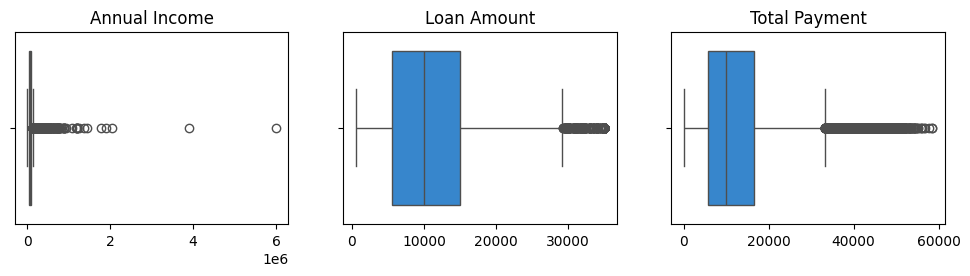

In [16]:
#outlier detection using boxplots
fig,axs=plt.subplots(nrows=1,ncols=3,figsize=(12,2.5))
sns.boxplot(data=df,x='annual_income',ax=axs[0])
axs[0].set_title('Annual Income')
axs[0].set_xlabel('')
sns.boxplot(data=df,x='loan_amount',ax=axs[1])
axs[1].set_title('Loan Amount')
axs[1].set_xlabel('')
sns.boxplot(data=df,x='total_payment',ax=axs[2])
axs[2].set_title('Total Payment')
axs[2].set_xlabel('')
plt.savefig('charts/01_outlier_boxplots.png',dpi=150,bbox_inches='tight')
plt.show()

In [17]:
#counting outliers in annual income using the IQR rule
q1=df['annual_income'].quantile(0.25)
q3=df['annual_income'].quantile(0.75)
iqr=q3-q1
upper_bound=q3+(1.5*iqr)
outlier_count=(df['annual_income']>upper_bound).sum()
print(f'Upper bound for annual income: ${upper_bound:,.0f}')
print(f'Loans above the upper bound: {outlier_count} ({round(outlier_count/len(df)*100,1)}%)')
print(f'Highest income before treatment: ${df["annual_income"].max():,.0f}')

Upper bound for annual income: $145,751
Loans above the upper bound: 1824 (4.7%)
Highest income before treatment: $6,000,000


In [18]:
#capping the extreme incomes at the upper bound
df['annual_income']=np.where(df['annual_income']>upper_bound,upper_bound,df['annual_income'])
print(f'Highest income after treatment: ${df["annual_income"].max():,.0f}')

Highest income after treatment: $145,751


**Insights**
- **Annual income has 1,824 outliers (4.7%)**, with a few incomes of several million dollars that would distort averages and charts. They are **capped at about \$145,751** (the IQR upper limit).
- `loan_amount` and `total_payment` also show points above the box, but these are **valid values** (the platform's maximum loan is \$35,000 and payments follow the loan size), so they are left unchanged. This also means the funded and received totals stay exactly the same as the dashboard.

## 4. Feature Engineering

In [19]:
#date features
df['month']=df['issue_date'].dt.month
df['month_name']=df['issue_date'].dt.month_name()

#good loan = Current or Fully Paid, bad loan = Charged Off (same rule as the dashboard)
df['loan_category']=np.where(df['loan_status']=='Charged Off','Bad Loan','Good Loan')
df['is_bad']=np.where(df['loan_status']=='Charged Off',1,0)

#percentage versions of the rates
df['int_rate_pct']=df['int_rate']*100
df['dti_pct']=df['dti']*100

#profit or loss on each loan (money received - money lent)
df['net_return']=df['total_payment']-df['loan_amount']

In [20]:
#creating bands for income, DTI and loan amount
df['income_band']=pd.cut(df['annual_income'],bins=[0,30000,50000,75000,100000,np.inf],labels=['<30K','30-50K','50-75K','75-100K','100K+'])
df['dti_band']=pd.cut(df['dti'],bins=[-0.01,0.10,0.15,0.20,0.25,1],labels=['<10%','10-15%','15-20%','20-25%','25%+'])
df['amount_band']=pd.cut(df['loan_amount'],bins=[0,5000,10000,15000,20000,40000],labels=['<5K','5-10K','10-15K','15-20K','20K+'])

In [21]:
#loans that are still being repaid ('Current') have not reached their final result yet,
#so for risk and profit analysis we use only loans that are finished (Fully Paid or Charged Off)
df_resolved=df[df['loan_status']!='Current']
overall_rate=df_resolved['is_bad'].mean()*100
print(f'Finished loans used for risk and profit analysis: {len(df_resolved)}')
print(f'Overall charge-off rate of finished loans: {round(overall_rate,2)}%')

Finished loans used for risk and profit analysis: 37478
Overall charge-off rate of finished loans: 14.23%


**Insights**
- **Good loans** = Fully Paid + Current. **Bad loans** = Charged Off. This is the same definition used in the dashboard.
- The 1,098 `Current` loans (all 60-month loans) are still being repaid, so their `total_payment` is incomplete. They are **left out of the risk and profit analysis**, which uses the **37,478 finished loans**.
- The **charge-off rate of finished loans is 14.23%**, slightly above the 13.82% on the dashboard, because the dashboard divides by *all* loans including Current ones.

## 5. Key Performance Indicators (KPIs)

These are the same KPIs shown on the dashboard, rebuilt in Python to cross-check the numbers.

In [22]:
#Total number of loan applications
total_apps=df['id'].count()
print(f'Total Applications: {total_apps}')

#Total Funded Amount
total_funded=df['loan_amount'].sum()
print(f'Total Funded Amount: ${round(total_funded/1000000,2)}M')

#Total Received Amount
total_received=df['total_payment'].sum()
print(f'Total Received Amount: ${round(total_received/1000000,2)}M')

#Average Interest rate
print(f'Avg Interest Rate: {round(df["int_rate"].mean()*100,2)}%')

#Average DTI(Debt to income ratio)
print(f'Avg DTI: {round(df["dti"].mean()*100,2)}%')

Total Applications: 38576
Total Funded Amount: $435.76M
Total Received Amount: $473.07M
Avg Interest Rate: 12.05%
Avg DTI: 13.33%


In [23]:
#monthly summary
monthly=df.groupby('month').agg(applications=('id','count'),funded=('loan_amount','sum'),received=('total_payment','sum'),avg_int_rate=('int_rate','mean'),avg_dti=('dti','mean'))
monthly

,applications,funded,received,avg_int_rate,avg_dti
month,,,,,
1,2332,25031650,27578836,0.114619,0.129370
2,2279,24647825,27717745,0.117216,0.134093
3,2627,28875700,32264400,0.118583,0.132156
4,2755,29800800,32495533,0.117409,0.132194
5,2911,31738350,33750523,0.122578,0.133337
6,3184,34161475,36164533,0.122742,0.132438
7,3366,35813900,38827220,0.122372,0.132948
8,3441,38149600,42682218,0.123002,0.133532
9,3536,40907725,43983948,0.120032,0.132978


In [24]:
#Month-to-date (December) and Month-over-month change (December vs November)
dec=monthly.loc[12]
nov=monthly.loc[11]
mom=(dec-nov)/nov*100

print(f'MTD Applications: {int(dec["applications"])}  | MoM: {round(mom["applications"],1)}%')
print(f'MTD Funded Amount: ${round(dec["funded"]/1000000,1)}M  | MoM: {round(mom["funded"],1)}%')
print(f'MTD Received Amount: ${round(dec["received"]/1000000,1)}M  | MoM: {round(mom["received"],1)}%')
print(f'MTD Avg Interest Rate: {round(dec["avg_int_rate"]*100,2)}%  | MoM: {round(mom["avg_int_rate"],1)}%')
print(f'MTD Avg DTI: {round(dec["avg_dti"]*100,2)}%  | MoM: {round(mom["avg_dti"],1)}%')

MTD Applications: 4314  | MoM: 6.9%
MTD Funded Amount: $54.0M  | MoM: 13.0%
MTD Received Amount: $58.1M  | MoM: 15.8%
MTD Avg Interest Rate: 12.36%  | MoM: 3.5%
MTD Avg DTI: 13.67%  | MoM: 2.7%


In [25]:
#Good loan vs Bad loan
good=df[df['loan_category']=='Good Loan']
bad=df[df['loan_category']=='Bad Loan']

print(f'Good Loan %: {round(len(good)/len(df)*100,2)}%')
print(f'Good Loan Applications: {len(good)}')
print(f'Good Loan Funded Amount: ${round(good["loan_amount"].sum()/1000000,2)}M')
print(f'Good Loan Received Amount: ${round(good["total_payment"].sum()/1000000,2)}M')
print()
print(f'Bad Loan %: {round(len(bad)/len(df)*100,2)}%')
print(f'Bad Loan Applications: {len(bad)}')
print(f'Bad Loan Funded Amount: ${round(bad["loan_amount"].sum()/1000000,2)}M')
print(f'Bad Loan Received Amount: ${round(bad["total_payment"].sum()/1000000,2)}M')

Good Loan %: 86.18%
Good Loan Applications: 33243
Good Loan Funded Amount: $370.22M
Good Loan Received Amount: $435.79M

Bad Loan %: 13.82%
Bad Loan Applications: 5333
Bad Loan Funded Amount: $65.53M
Bad Loan Received Amount: $37.28M


In [26]:
#summary table by loan status (same as the dashboard summary page)
status_table=df.groupby('loan_status').agg(applications=('id','count'),funded=('loan_amount','sum'),received=('total_payment','sum'),avg_int_rate=('int_rate','mean'),avg_dti=('dti','mean'))
status_table['avg_int_rate']=(status_table['avg_int_rate']*100).round(2)
status_table['avg_dti']=(status_table['avg_dti']*100).round(2)
status_table

,applications,funded,received,avg_int_rate,avg_dti
loan_status,,,,,
Charged Off,5333,65532225,37284763,13.88,14.00
Current,1098,18866500,24199914,15.10,14.72
Fully Paid,32145,351358350,411586256,11.64,13.17


**Insights**
- The Python numbers **match the dashboard exactly**: 38.6K applications, \$435.8M funded, \$473.1M received, 12.05% average interest rate and 13.33% average DTI.
- **December vs November:** applications +6.9%, funded amount +13.0%, received amount +15.8%, average interest rate +3.5% and average DTI +2.7%.
- **86.18% of loans are good and 13.82% are bad.** Bad loans: 5,333 loans, \$65.5M lent and only \$37.3M received back.
- The lender received \$37.3M back on \$65.5M lent to borrowers who defaulted, so **about \$28.2M of principal was lost** on charged-off loans.

## 6. Univariate Analysis

### Loan Status

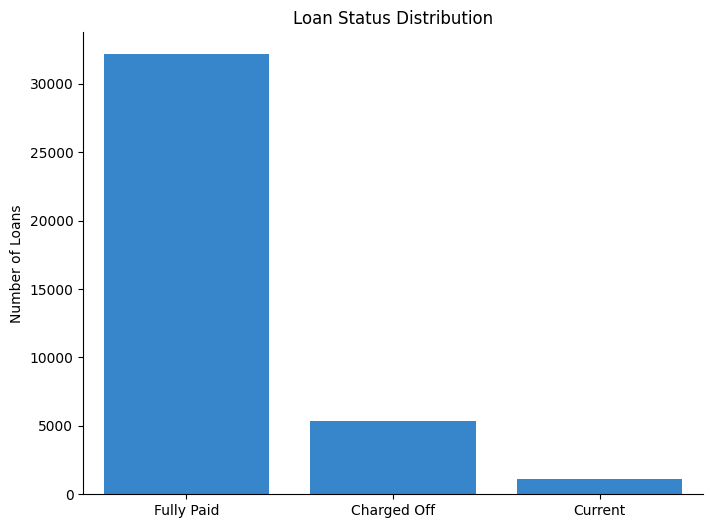

In [27]:
#loan status distribution
status_counts=df['loan_status'].value_counts()
plt.figure(figsize=(8,6))
ax=sns.barplot(x=status_counts.index,y=status_counts.values)
plt.title('Loan Status Distribution')
plt.xlabel('')
plt.ylabel('Number of Loans')
plt.gca().spines[['top','right']].set_visible(False)
plt.savefig('charts/02_loan_status.png',dpi=150,bbox_inches='tight')
plt.show()

**Insights**
- **Fully Paid loans dominate (83.3%)**, followed by Charged Off (13.8%) and Current (2.8%).
- Roughly **1 in every 7 loans ends in a charge-off**, which is the main risk the rest of this analysis tries to explain.

### Loan Amount

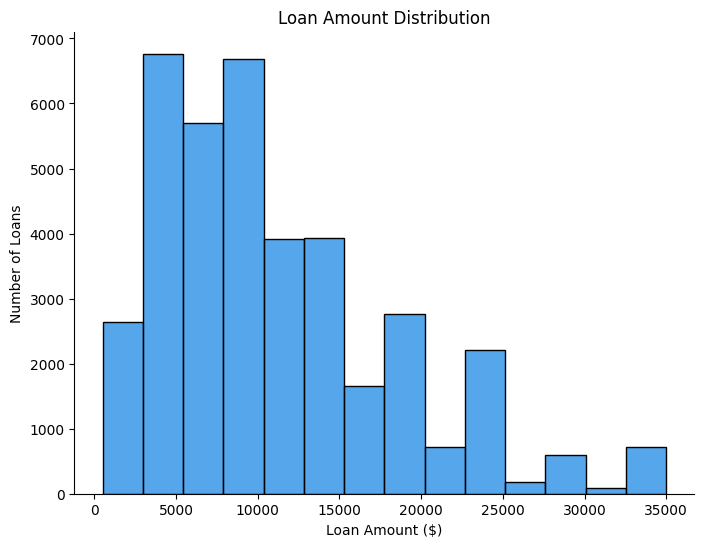

In [28]:
#loan amount distribution
plt.figure(figsize=(8,6))
sns.histplot(data=df,x='loan_amount',binwidth=2500)
plt.title('Loan Amount Distribution')
plt.xlabel('Loan Amount ($)')
plt.ylabel('Number of Loans')
plt.gca().spines[['top','right']].set_visible(False)
plt.savefig('charts/03_loan_amount_distribution.png',dpi=150,bbox_inches='tight')
plt.show()

In [29]:
df['loan_amount'].describe()

count    38576.000000
mean     11296.066855
std       7460.746022
min        500.000000
25%       5500.000000
50%      10000.000000
75%      15000.000000
max      35000.000000
Name: loan_amount, dtype: float64

**Insights**
- The distribution is **right-skewed**: most loans are small, with a tail of larger loans up to \$35,000.
- The **median loan is \$10,000** and the average is about \$11,296; half of all loans fall between \$5,500 and \$15,000.

### Interest Rate

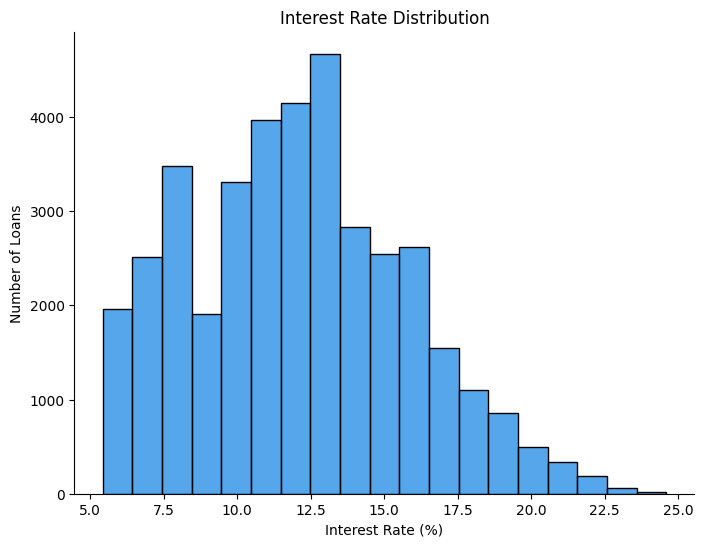

In [30]:
#interest rate distribution
plt.figure(figsize=(8,6))
sns.histplot(data=df,x='int_rate_pct',binwidth=1)
plt.title('Interest Rate Distribution')
plt.xlabel('Interest Rate (%)')
plt.ylabel('Number of Loans')
plt.gca().spines[['top','right']].set_visible(False)
plt.savefig('charts/04_interest_rate_distribution.png',dpi=150,bbox_inches='tight')
plt.show()

In [31]:
df['int_rate_pct'].describe()

count    38576.000000
mean        12.048831
std          3.716412
min          5.420000
25%          9.320000
50%         11.860000
75%         14.590000
max         24.590000
Name: int_rate_pct, dtype: float64

**Insights**
- Interest rates range from **5.4% to 24.6%**, with an average of 12.05%.
- Half of all loans are priced between **9.3% and 14.6%**; very few loans carry rates above 20%.

### Debt-to-Income Ratio (DTI) and Annual Income

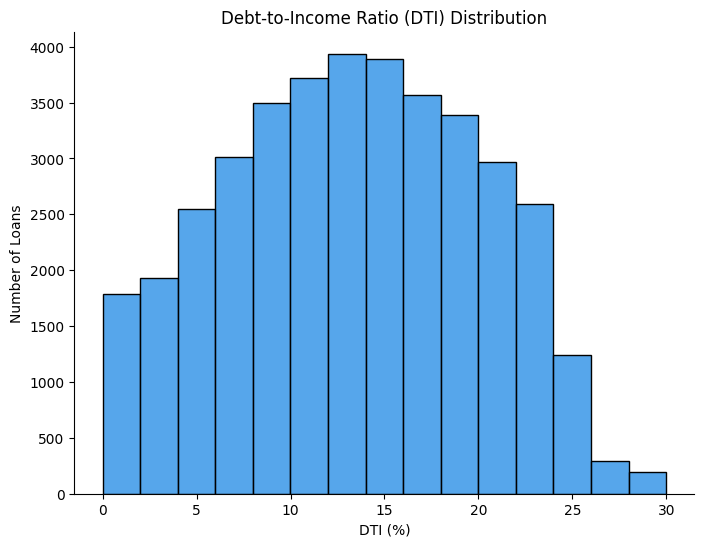

In [32]:
#dti distribution
plt.figure(figsize=(8,6))
sns.histplot(data=df,x='dti_pct',binwidth=2)
plt.title('Debt-to-Income Ratio (DTI) Distribution')
plt.xlabel('DTI (%)')
plt.ylabel('Number of Loans')
plt.gca().spines[['top','right']].set_visible(False)
plt.savefig('charts/05_dti_distribution.png',dpi=150,bbox_inches='tight')
plt.show()

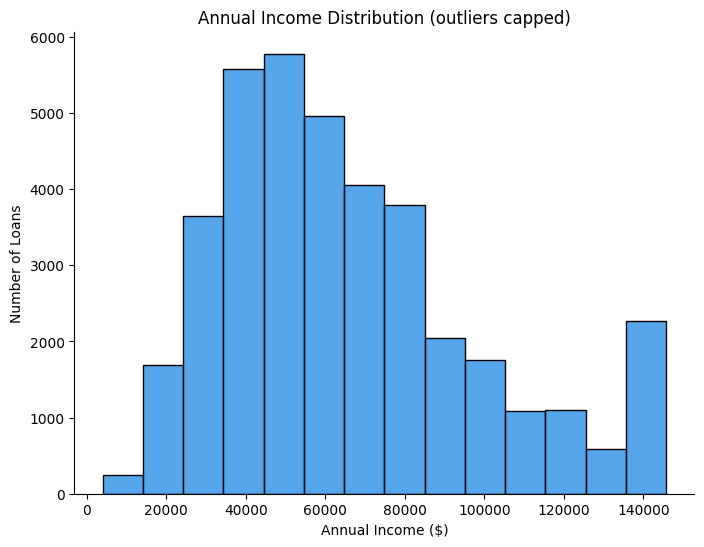

In [33]:
#annual income distribution (after capping outliers)
plt.figure(figsize=(8,6))
sns.histplot(data=df,x='annual_income',binwidth=10000)
plt.title('Annual Income Distribution (outliers capped)')
plt.xlabel('Annual Income ($)')
plt.ylabel('Number of Loans')
plt.gca().spines[['top','right']].set_visible(False)
plt.savefig('charts/06_income_distribution.png',dpi=150,bbox_inches='tight')
plt.show()

**Insights**
- **DTI** is roughly bell-shaped, centred around 13–14%, and tapers off after 25%. No borrower is above 30%, so the lender already applies a DTI ceiling.
- **Annual income** is right-skewed with a median of **\$60,000**; most borrowers earn between \$40,000 and \$85,000. The tall bar at the far right is not a real peak – it is the 1,824 outlier incomes that were capped at \$145,751.

### Grade

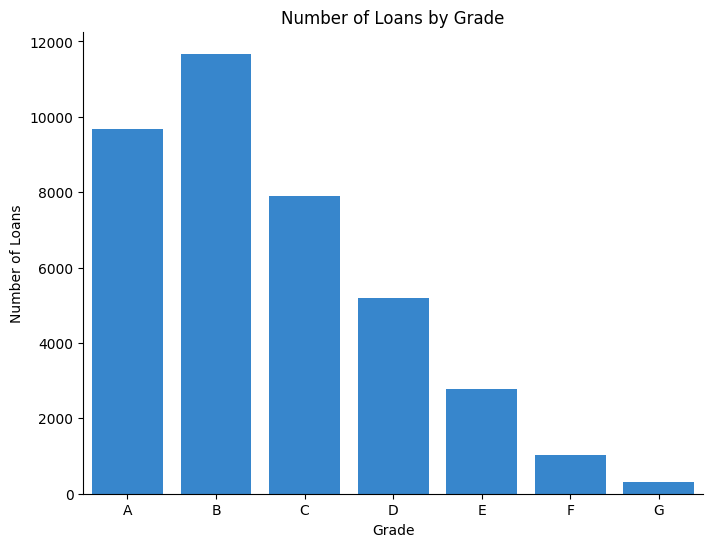

In [34]:
#number of loans by grade
plt.figure(figsize=(8,6))
ax=sns.countplot(data=df,x='grade',order=['A','B','C','D','E','F','G'])
plt.title('Number of Loans by Grade')
plt.xlabel('Grade')
plt.ylabel('Number of Loans')
plt.gca().spines[['top','right']].set_visible(False)
plt.savefig('charts/07_loans_by_grade.png',dpi=150,bbox_inches='tight')
plt.show()

**Insights**
- **Grade B is the biggest group (11,674 loans, 30.3%)**, followed by A (25.1%) and C (20.5%).
- Grades A and B together make up **55.4% of all loans**. Grades D to G are about 24% of loans and 31% of the money lent, and grade G is tiny (313 loans).

### Purpose

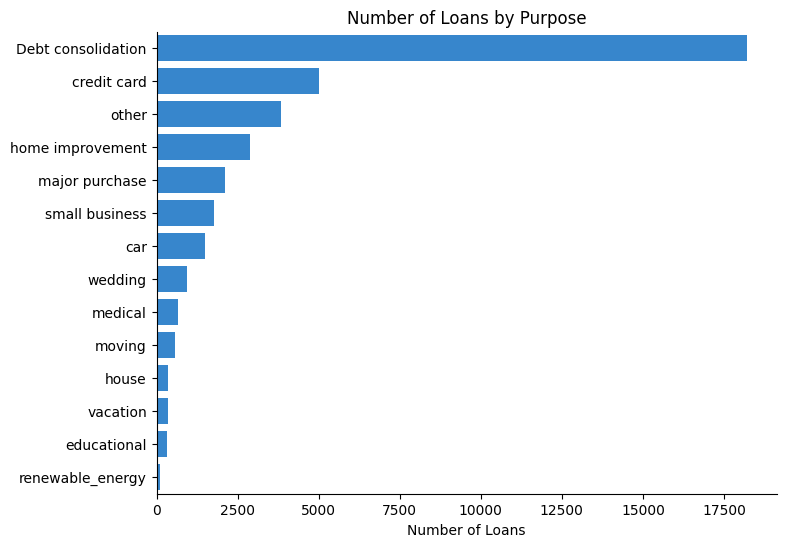

In [35]:
#number of loans by purpose
plt.figure(figsize=(8,6))
ax=sns.countplot(data=df,y='purpose',order=df['purpose'].value_counts().index)
plt.title('Number of Loans by Purpose')
plt.xlabel('Number of Loans')
plt.ylabel('')
plt.gca().spines[['top','right']].set_visible(False)
plt.savefig('charts/08_loans_by_purpose.png',dpi=150,bbox_inches='tight')
plt.show()

In [36]:
#share of applications and funded amount by purpose
purpose_share=pd.DataFrame({'apps_%':df['purpose'].value_counts(normalize=True)*100,'funded_%':df.groupby('purpose')['loan_amount'].sum()/df['loan_amount'].sum()*100})
purpose_share.sort_values('apps_%',ascending=False).round(1).head(5)

,apps_%,funded_%
purpose,,
Debt consolidation,47.2,53.3
credit card,13.0,13.5
other,9.9,7.1
home improvement,7.5,7.7
major purchase,5.5,4.0


**Insights**
- **Debt consolidation is the main reason people borrow: 47.2% of applications and 53.3% of the money lent.**
- Adding the `credit card` purpose, about **60% of loans are used to repay existing debt**. Smaller purposes like wedding, vacation, educational and renewable energy together are only a small part of the book.

### Term

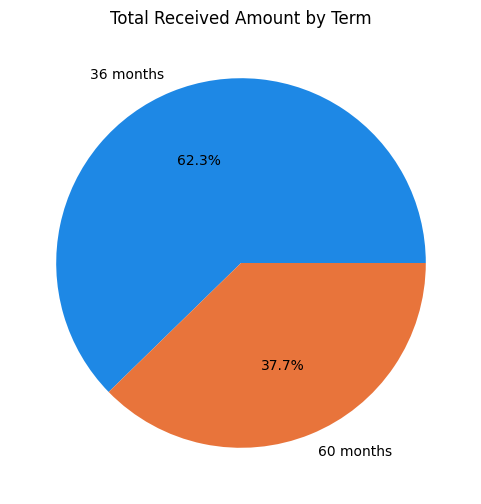

In [37]:
#total received amount by term
term_received=df.groupby('term')['total_payment'].sum()
plt.figure(figsize=(6,6))
plt.pie(term_received,labels=term_received.index,autopct='%1.1f%%')
plt.title('Total Received Amount by Term')
plt.savefig('charts/09_received_by_term.png',dpi=150,bbox_inches='tight')
plt.show()

In [38]:
#share of loans by term
df['term'].value_counts(normalize=True)*100

term
36 months    73.198362
60 months    26.801638
Name: proportion, dtype: float64

**Insights**
- **36-month loans are 73.2% of loans and bring in 62.3% (\$294.7M) of the money received.** 60-month loans are 26.8% of loans but 37.7% (\$178.4M) of the money received, because they are larger.
- This matches the pie chart on the dashboard Overview page. (The earlier version of this chart used `loan_amount` instead of `total_payment`, so it did not match its title.)

## 7. Time-Based Analysis

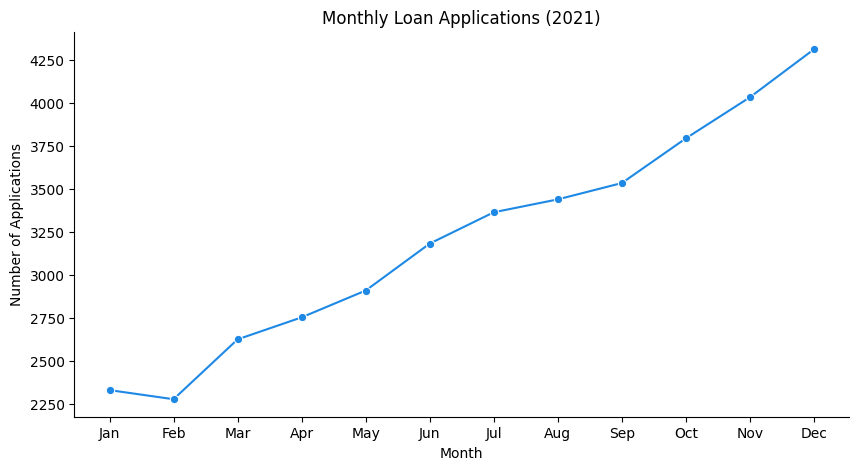

In [39]:
#month labels used in all the time charts
months=['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']

#monthly loan applications
plt.figure(figsize=(10,5))
sns.lineplot(x=months,y=monthly['applications'].values,marker='o')
plt.title('Monthly Loan Applications (2021)')
plt.xlabel('Month')
plt.ylabel('Number of Applications')
plt.gca().spines[['top','right']].set_visible(False)
plt.savefig('charts/10_monthly_applications.png',dpi=150,bbox_inches='tight')
plt.show()

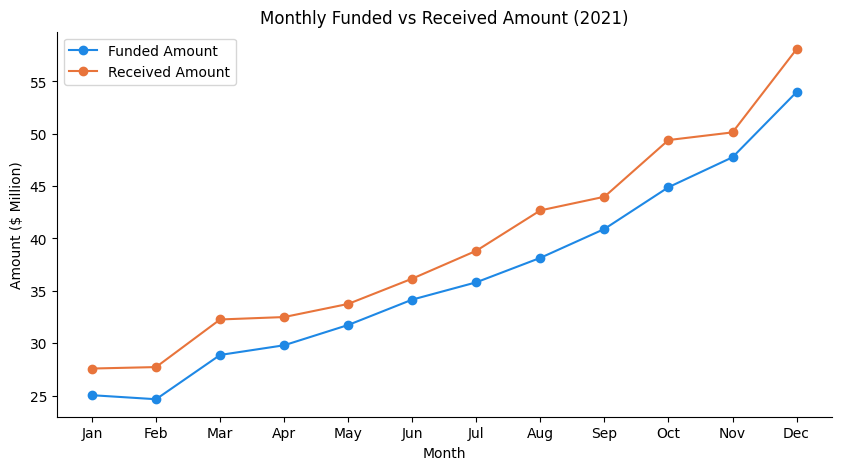

In [40]:
#monthly funded amount vs received amount
plt.figure(figsize=(10,5))
plt.plot(months,monthly['funded'].values/1000000,marker='o',label='Funded Amount')
plt.plot(months,monthly['received'].values/1000000,marker='o',label='Received Amount')
plt.title('Monthly Funded vs Received Amount (2021)')
plt.xlabel('Month')
plt.ylabel('Amount ($ Million)')
plt.legend()
plt.gca().spines[['top','right']].set_visible(False)
plt.savefig('charts/11_monthly_funded_vs_received.png',dpi=150,bbox_inches='tight')
plt.show()

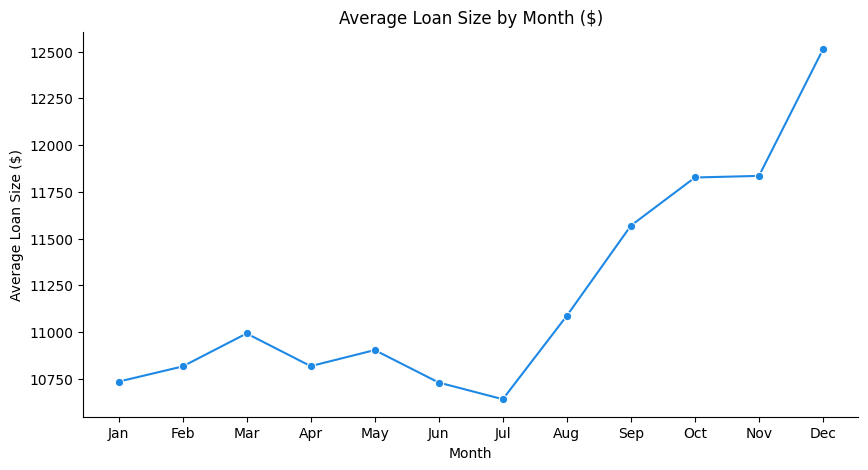

In [41]:
#average loan size by month
monthly['avg_loan']=monthly['funded']/monthly['applications']

plt.figure(figsize=(10,5))
sns.lineplot(x=months,y=monthly['avg_loan'].values,marker='o')
plt.title('Average Loan Size by Month ($)')
plt.xlabel('Month')
plt.ylabel('Average Loan Size ($)')
plt.gca().spines[['top','right']].set_visible(False)
plt.savefig('charts/12_avg_loan_size_by_month.png',dpi=150,bbox_inches='tight')
plt.show()

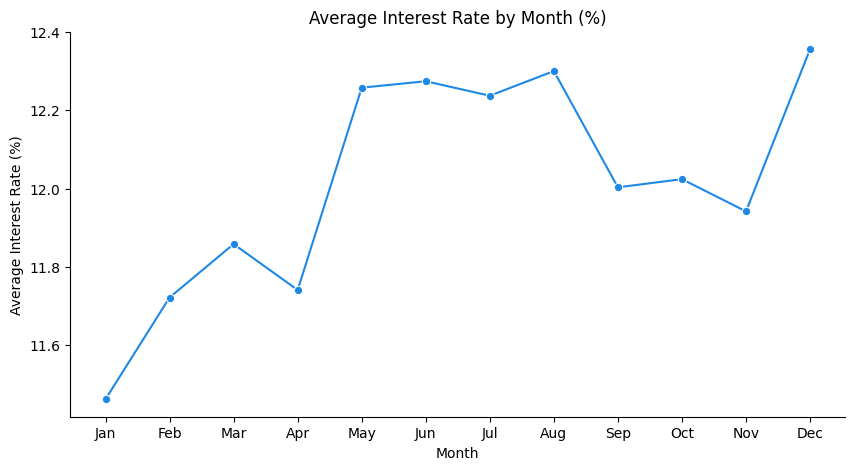

In [42]:
#average interest rate by month
plt.figure(figsize=(10,5))
sns.lineplot(x=months,y=monthly['avg_int_rate'].values*100,marker='o')
plt.title('Average Interest Rate by Month (%)')
plt.xlabel('Month')
plt.ylabel('Average Interest Rate (%)')
plt.gca().spines[['top','right']].set_visible(False)
plt.savefig('charts/12b_avg_int_rate_by_month.png',dpi=150,bbox_inches='tight')
plt.show()

In [43]:
#growth from January to December
first=monthly.loc[1]
last=monthly.loc[12]
print(f'Applications: {int(first["applications"])} -> {int(last["applications"])}  ({round((last["applications"]/first["applications"]-1)*100)}% growth)')
print(f'Funded amount: ${round(first["funded"]/1000000,1)}M -> ${round(last["funded"]/1000000,1)}M  ({round((last["funded"]/first["funded"]-1)*100)}% growth)')
print(f'Average loan size: ${round(first["avg_loan"])} -> ${round(last["avg_loan"])}  ({round((last["avg_loan"]/first["avg_loan"]-1)*100)}% growth)')
print(f'Average interest rate: {round(first["avg_int_rate"]*100,2)}% -> {round(last["avg_int_rate"]*100,2)}%')

Applications: 2332 -> 4314  (85% growth)
Funded amount: $25.0M -> $54.0M  (116% growth)
Average loan size: $10734 -> $12513  (17% growth)
Average interest rate: 11.46% -> 12.36%


**Insights**
- **Strong, steady growth.** Applications rose almost every month, from **2,332 in January to 4,314 in December (+85%)**. The only dip is February (2,279).
- **Funded amount grew faster than applications (\$25.0M to \$54.0M, +116%)** because the **average loan size increased from about \$10,700 to \$12,500 (+17%)**.
- Received amount is above funded amount in every month, because repayments include interest.
- The **average interest rate also rose** from 11.5% in January to 12.4% in December. Growth is coming with bigger and more expensive loans, which is something to watch (see Section 8).

## 8. Risk Analysis (Charge-off Rate)

Charge-off rate = share of **finished loans** (Fully Paid + Charged Off) that were charged off. The overall charge-off rate is **14.2%**, so any bar above that is riskier than average.

### By Grade

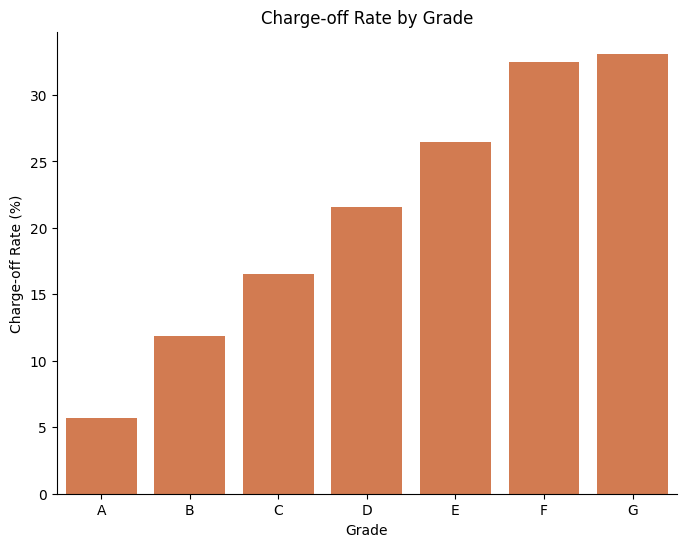

grade
A     5.7
B    11.8
C    16.6
D    21.6
E    26.5
F    32.5
G    33.1
Name: is_bad, dtype: float64

In [44]:
#charge-off rate by grade
grade_risk=df_resolved.groupby('grade')['is_bad'].mean()*100

plt.figure(figsize=(8,6))
ax=sns.barplot(x=grade_risk.index,y=grade_risk.values,color='#E8743B')
plt.title('Charge-off Rate by Grade')
plt.xlabel('Grade')
plt.ylabel('Charge-off Rate (%)')
plt.gca().spines[['top','right']].set_visible(False)
plt.savefig('charts/13_chargeoff_by_grade.png',dpi=150,bbox_inches='tight')
plt.show()
grade_risk.round(1)

**Insights**
- Risk rises with every grade: **A 5.7% → B 11.8% → C 16.6% → D 21.6% → E 26.5% → F 32.5% → G 33.1%**.
- A grade F or G borrower is about **6 times more likely to default** than a grade A borrower. The grading system clearly works as a risk signal.

### By Term

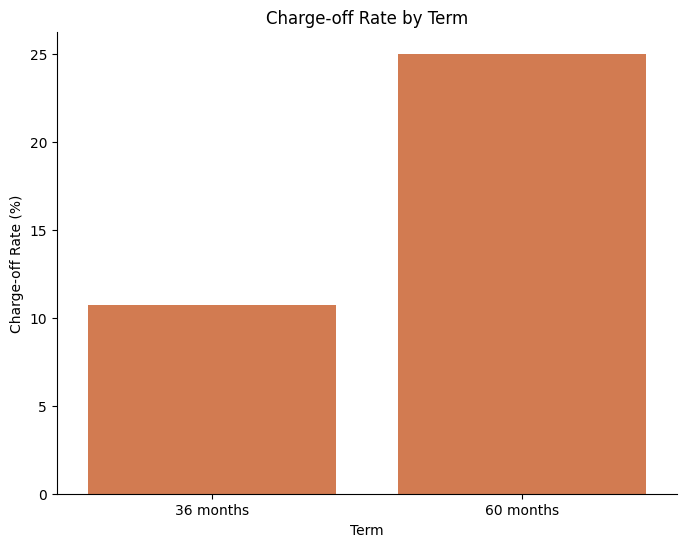

term
36 months    10.7
60 months    25.0
Name: is_bad, dtype: float64

In [45]:
#charge-off rate by term
term_risk=df_resolved.groupby('term')['is_bad'].mean()*100

plt.figure(figsize=(8,6))
ax=sns.barplot(x=term_risk.index,y=term_risk.values,color='#E8743B')
plt.title('Charge-off Rate by Term')
plt.xlabel('Term')
plt.ylabel('Charge-off Rate (%)')
plt.gca().spines[['top','right']].set_visible(False)
plt.savefig('charts/14_chargeoff_by_term.png',dpi=150,bbox_inches='tight')
plt.show()
term_risk.round(1)

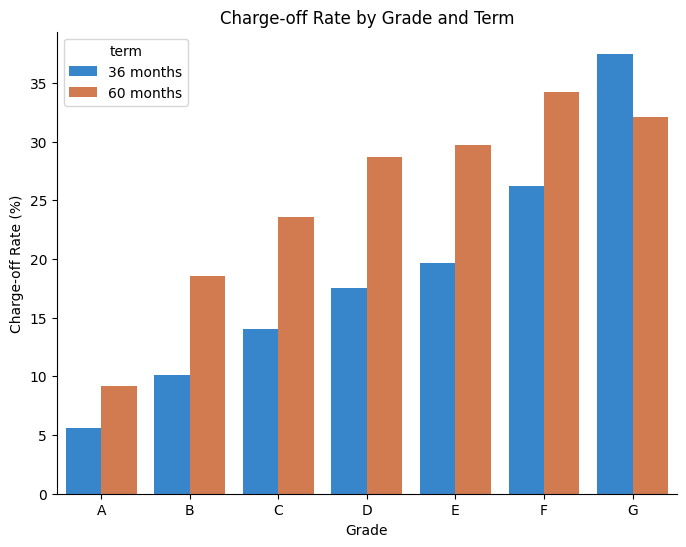

In [46]:
#charge-off rate by grade and term together
grade_term=df_resolved.groupby(['grade','term'])['is_bad'].mean().reset_index()
grade_term['charge_off_rate']=grade_term['is_bad']*100

plt.figure(figsize=(8,6))
sns.barplot(data=grade_term,x='grade',y='charge_off_rate',hue='term')
plt.title('Charge-off Rate by Grade and Term')
plt.xlabel('Grade')
plt.ylabel('Charge-off Rate (%)')
plt.gca().spines[['top','right']].set_visible(False)
plt.savefig('charts/15_chargeoff_grade_term.png',dpi=150,bbox_inches='tight')
plt.show()

In [47]:
grade_term[['grade','term','charge_off_rate']].round(1)

,grade,term,charge_off_rate
0,A,36 months,5.6
1,A,60 months,9.2
2,B,36 months,10.2
3,B,60 months,18.5
4,C,36 months,14.0
5,C,60 months,23.5
6,D,36 months,17.5
7,D,60 months,28.7
8,E,36 months,19.7
9,E,60 months,29.7


**Insights**
- **60-month loans are far riskier: 25.0% charge-off vs 10.7% for 36-month loans** (22.3% of all 60-month loans, if the Current ones are included).
- The chart shows this is **not just a grade effect**: in every grade from A to F the 60-month loan is worse (for example grade C: 23.5% vs 14.0%). Even a grade A loan jumps from 5.6% to 9.2% when the term is 60 months.
- Note: all Current loans are 60-month loans, so the 60-month rate is measured on loans that have already finished and may be slightly overstated.

### By Purpose

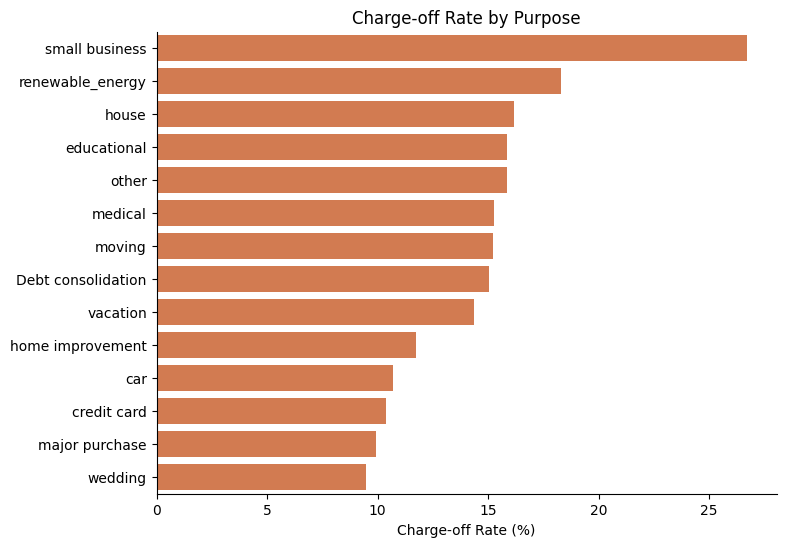

purpose
small business        26.7
renewable_energy      18.3
house                 16.2
educational           15.9
other                 15.8
medical               15.3
moving                15.2
Debt consolidation    15.0
vacation              14.4
home improvement      11.8
car                   10.7
credit card           10.4
major purchase         9.9
wedding                9.5
Name: is_bad, dtype: float64

In [48]:
#charge-off rate by purpose
purpose_risk=(df_resolved.groupby('purpose')['is_bad'].mean()*100).sort_values(ascending=False)

plt.figure(figsize=(8,6))
ax=sns.barplot(x=purpose_risk.values,y=purpose_risk.index,color='#E8743B')
plt.title('Charge-off Rate by Purpose')
plt.xlabel('Charge-off Rate (%)')
plt.ylabel('')
plt.gca().spines[['top','right']].set_visible(False)
plt.savefig('charts/16_chargeoff_by_purpose.png',dpi=150,bbox_inches='tight')
plt.show()
purpose_risk.round(1)

**Insights**
- **Small business loans are by far the riskiest: 26.7% charge-off**, almost double the overall rate.
- Renewable energy (18.3%) and house (16.2%) also look high, but they are very small groups (93 and 352 loans), so they should be read with care.
- The safest purposes are **wedding (9.5%), major purchase (9.9%), credit card (10.4%) and car (10.7%)**.
- Debt consolidation, the biggest purpose, sits just above average at 15.0%.

### By Loan Amount, Income and DTI

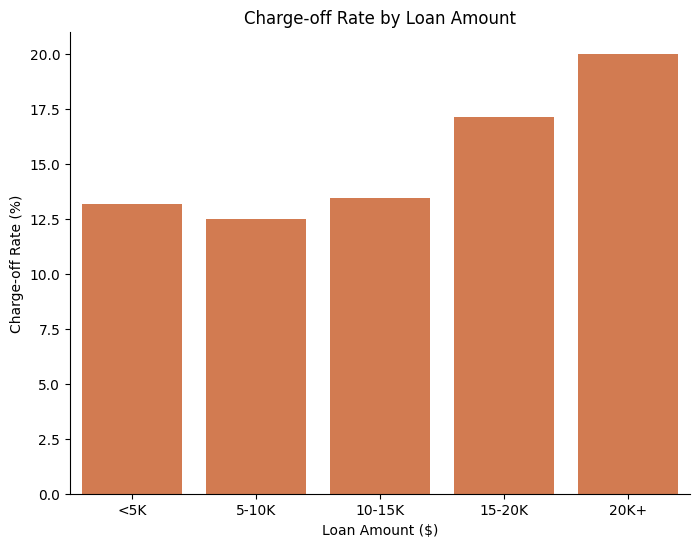

amount_band
<5K       13.2
5-10K     12.5
10-15K    13.5
15-20K    17.1
20K+      20.0
Name: is_bad, dtype: float64

In [49]:
#charge-off rate by loan amount band
amount_risk=df_resolved.groupby('amount_band')['is_bad'].mean()*100

plt.figure(figsize=(8,6))
ax=sns.barplot(x=amount_risk.index,y=amount_risk.values,color='#E8743B')
plt.title('Charge-off Rate by Loan Amount')
plt.xlabel('Loan Amount ($)')
plt.ylabel('Charge-off Rate (%)')
plt.gca().spines[['top','right']].set_visible(False)
plt.savefig('charts/17_chargeoff_by_amount.png',dpi=150,bbox_inches='tight')
plt.show()
amount_risk.round(1)

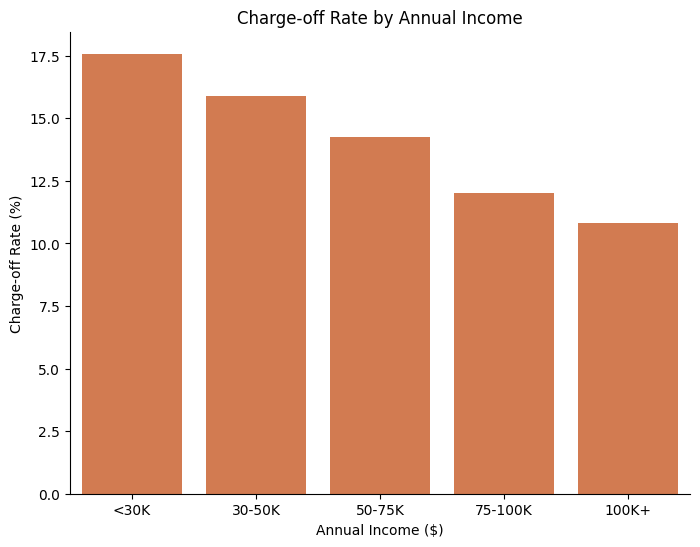

income_band
<30K       17.6
30-50K     15.9
50-75K     14.2
75-100K    12.0
100K+      10.8
Name: is_bad, dtype: float64

In [50]:
#charge-off rate by annual income band
income_risk=df_resolved.groupby('income_band')['is_bad'].mean()*100

plt.figure(figsize=(8,6))
ax=sns.barplot(x=income_risk.index,y=income_risk.values,color='#E8743B')
plt.title('Charge-off Rate by Annual Income')
plt.xlabel('Annual Income ($)')
plt.ylabel('Charge-off Rate (%)')
plt.gca().spines[['top','right']].set_visible(False)
plt.savefig('charts/18_chargeoff_by_income.png',dpi=150,bbox_inches='tight')
plt.show()
income_risk.round(1)

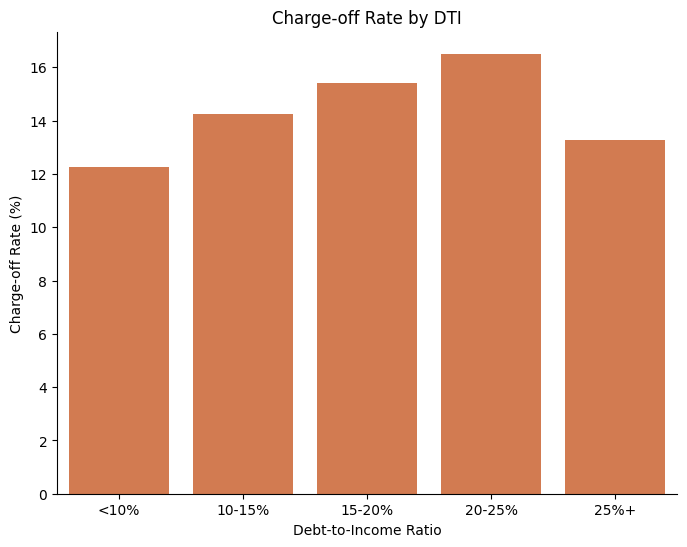

dti_band
<10%      12.3
10-15%    14.3
15-20%    15.4
20-25%    16.5
25%+      13.3
Name: is_bad, dtype: float64

In [51]:
#charge-off rate by DTI band
dti_risk=df_resolved.groupby('dti_band')['is_bad'].mean()*100

plt.figure(figsize=(8,6))
ax=sns.barplot(x=dti_risk.index,y=dti_risk.values,color='#E8743B')
plt.title('Charge-off Rate by DTI')
plt.xlabel('Debt-to-Income Ratio')
plt.ylabel('Charge-off Rate (%)')
plt.gca().spines[['top','right']].set_visible(False)
plt.savefig('charts/19_chargeoff_by_dti.png',dpi=150,bbox_inches='tight')
plt.show()
dti_risk.round(1)

In [52]:
#number of finished loans in each DTI band (to check the small 25%+ group)
df_resolved['dti_band'].value_counts().sort_index()

dti_band
<10%      12514
10-15%     9393
15-20%     8585
20-25%     6390
25%+        596
Name: count, dtype: int64

**Insights**
- **Bigger loans are riskier:** loans below \$10K have about 12.5–13% charge-off, but this climbs to **17.1% for \$15–20K and 20.0% for loans above \$20K**.
- **Higher income means lower risk:** 17.6% for incomes under \$30K, falling steadily to **10.8% for incomes above \$100K**.
- **Higher DTI means higher risk:** 12.3% below 10% DTI rising to 16.5% at 20–25% DTI. The 25%+ group (only 596 loans) looks lower at 13.3%, but it is too small to trust.

### By Verification Status, Home Ownership and Employment Length

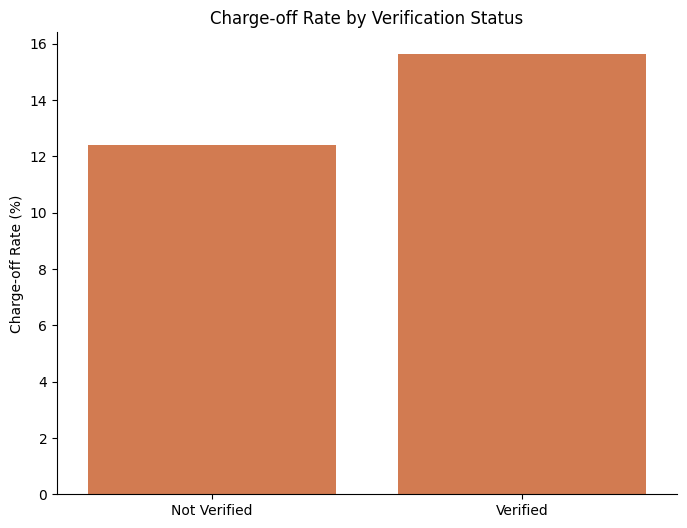

verification_status
Not Verified    12.4
Verified        15.6
Name: is_bad, dtype: float64

In [53]:
#charge-off rate by verification status
verification_risk=df_resolved.groupby('verification_status')['is_bad'].mean()*100

plt.figure(figsize=(8,6))
sns.barplot(x=verification_risk.index,y=verification_risk.values,color='#E8743B')
plt.title('Charge-off Rate by Verification Status')
plt.xlabel('')
plt.ylabel('Charge-off Rate (%)')
plt.gca().spines[['top','right']].set_visible(False)
plt.savefig('charts/20_chargeoff_by_verification.png',dpi=150,bbox_inches='tight')
plt.show()
verification_risk.round(1)

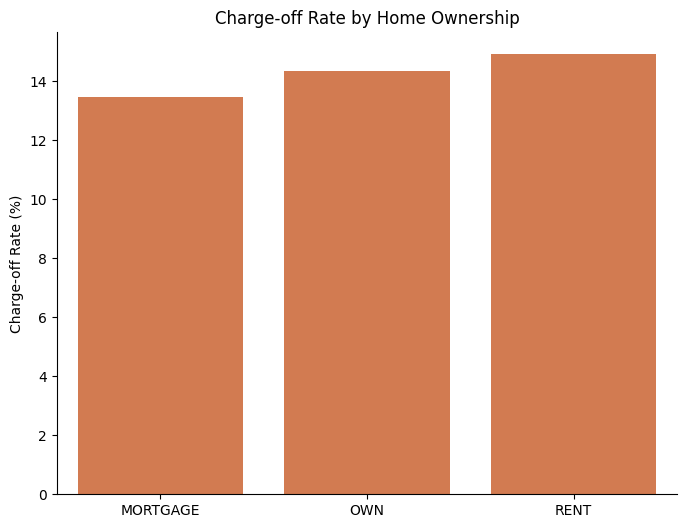

home_ownership
MORTGAGE    13.5
OWN         14.3
RENT        14.9
Name: is_bad, dtype: float64

In [54]:
#charge-off rate by home ownership (keeping only the three main groups)
home=df_resolved[df_resolved['home_ownership'].isin(['RENT','MORTGAGE','OWN'])]
home_risk=home.groupby('home_ownership')['is_bad'].mean()*100

plt.figure(figsize=(8,6))
sns.barplot(x=home_risk.index,y=home_risk.values,color='#E8743B')
plt.title('Charge-off Rate by Home Ownership')
plt.xlabel('')
plt.ylabel('Charge-off Rate (%)')
plt.gca().spines[['top','right']].set_visible(False)
plt.savefig('charts/20b_chargeoff_by_home_ownership.png',dpi=150,bbox_inches='tight')
plt.show()
home_risk.round(1)

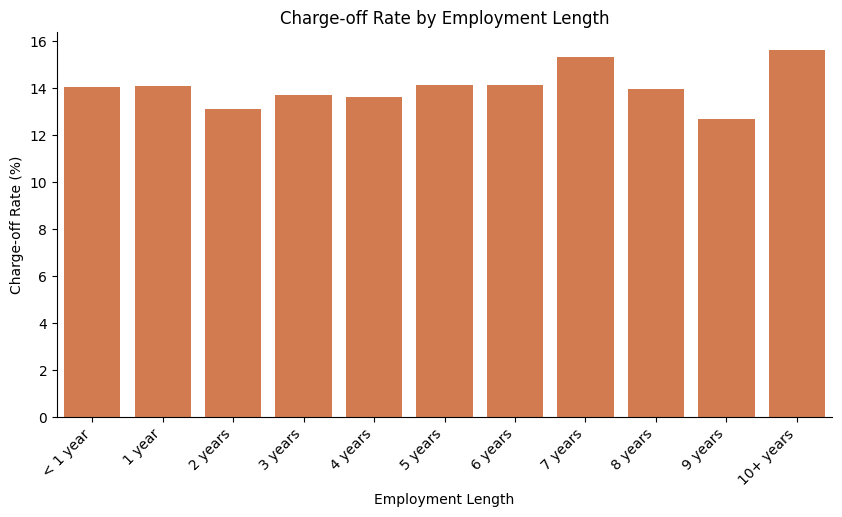

emp_length
< 1 year     14.0
1 year       14.1
2 years      13.1
3 years      13.7
4 years      13.6
5 years      14.1
6 years      14.1
7 years      15.3
8 years      14.0
9 years      12.7
10+ years    15.6
Name: is_bad, dtype: float64

In [55]:
#charge-off rate by employment length
emp_order=['< 1 year','1 year','2 years','3 years','4 years','5 years','6 years','7 years','8 years','9 years','10+ years']
emp_risk=(df_resolved.groupby('emp_length')['is_bad'].mean()*100).reindex(emp_order)

plt.figure(figsize=(10,5))
ax=sns.barplot(x=emp_risk.index,y=emp_risk.values,color='#E8743B')
plt.title('Charge-off Rate by Employment Length')
plt.xlabel('Employment Length')
plt.ylabel('Charge-off Rate (%)')
plt.xticks(rotation=45,ha='right')
plt.gca().spines[['top','right']].set_visible(False)
plt.savefig('charts/21_chargeoff_by_emp_length.png',dpi=150,bbox_inches='tight')
plt.show()
emp_risk.round(1)

In [56]:
#average interest rate by verification status (to understand the verification result)
df_resolved.groupby('verification_status')['int_rate_pct'].mean().round(1)

verification_status
Not Verified    11.2
Verified        12.5
Name: int_rate_pct, dtype: float64

**Insights**
- **Verified borrowers default more (15.6%) than Not Verified borrowers (12.4%)** – the opposite of what we would expect. Verified borrowers also pay a higher average interest rate (12.5% vs 11.2%), so the lender is probably verifying the riskier applicants. Verification is *not* removing risk on its own.
- **Home ownership** makes only a small difference: Rent 14.9%, Own 14.3%, Mortgage 13.5%.
- **Employment length** is a weak signal: every group sits between 12.7% and 15.6%, with no clear pattern. It should not be used on its own to approve or reject loans.

### Charged-off vs Fully Paid Borrowers

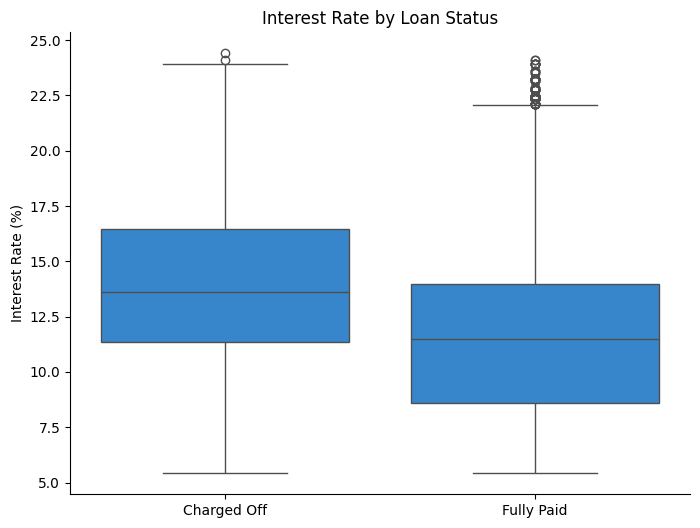

In [57]:
#interest rate of charged-off vs fully paid loans
plt.figure(figsize=(8,6))
sns.boxplot(data=df_resolved,x='loan_status',y='int_rate_pct')
plt.title('Interest Rate by Loan Status')
plt.xlabel('')
plt.ylabel('Interest Rate (%)')
plt.gca().spines[['top','right']].set_visible(False)
plt.savefig('charts/22_int_rate_by_status.png',dpi=150,bbox_inches='tight')
plt.show()

In [58]:
#typical (median) profile of charged-off vs fully paid borrowers
df_resolved.groupby('loan_status')[['int_rate_pct','dti_pct','annual_income','loan_amount','total_acc']].median().round(1)

,int_rate_pct,dti_pct,annual_income,loan_amount,total_acc
loan_status,,,,,
Charged Off,13.6,14.3,54000.0,10000.0,20.0
Fully Paid,11.5,13.2,60000.0,9600.0,21.0


**Insights**
- Charged-off loans carry a **higher median interest rate (13.6% vs 11.5%)**, a higher median DTI (14.3% vs 13.2%), a lower median income (\$54,000 vs \$60,000) and a slightly larger median loan (\$10,000 vs \$9,600).
- The profile of a risky borrower is clear: **lower income, higher DTI, larger loan, longer term and a lower grade.**

## 9. Profitability Analysis

Profit on a loan = money received − money lent. Only **finished loans** are used here. Return (ROI) = profit ÷ money lent. This is a simple return, not adjusted for how long the money was tied up.

### Profit from Good vs Bad Loans

In [59]:
#profit and loss by loan status (finished loans)
status_result=df_resolved.groupby('loan_status')[['loan_amount','total_payment']].sum()
status_result['net_result']=status_result['total_payment']-status_result['loan_amount']
status_result['net_result_$M']=(status_result['net_result']/1000000).round(1)
status_result['recovered_%']=(status_result['total_payment']/status_result['loan_amount']*100).round(1)
status_result

,loan_amount,total_payment,net_result,net_result_$M,recovered_%
loan_status,,,,,
Charged Off,65532225,37284763,-28247462,-28.2,56.9
Fully Paid,351358350,411586256,60227906,60.2,117.1


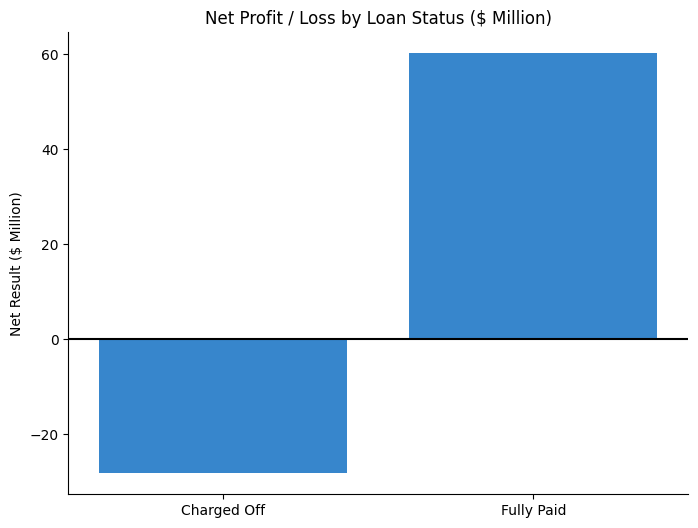

In [60]:
#net result of fully paid and charged-off loans
plt.figure(figsize=(8,6))
sns.barplot(x=status_result.index,y=status_result['net_result']/1000000)
plt.axhline(0,color='black')
plt.title('Net Profit / Loss by Loan Status ($ Million)')
plt.xlabel('')
plt.ylabel('Net Result ($ Million)')
plt.gca().spines[['top','right']].set_visible(False)
plt.savefig('charts/23_net_result_by_status.png',dpi=150,bbox_inches='tight')
plt.show()

In [61]:
#total profit and how much of it is lost to charge-offs
total_profit=status_result['net_result'].sum()
total_lent=status_result['loan_amount'].sum()
fully_paid_profit=status_result.loc['Fully Paid','net_result']
charged_off_loss=status_result.loc['Charged Off','net_result']
print(f'Net profit on finished loans: ${round(total_profit/1000000,1)}M')
print(f'Return on money lent: {round(total_profit/total_lent*100,1)}%')
print(f'Share of Fully Paid profit lost to charge-offs: {round(-charged_off_loss/fully_paid_profit*100)}%')

Net profit on finished loans: $32.0M
Return on money lent: 7.7%
Share of Fully Paid profit lost to charge-offs: 47%


**Insights**
- **Fully Paid loans earned +\$60.2M** (the lender got back 117% of the money lent). **Charged-off loans lost \$28.2M** (only 56.9% of the money was recovered).
- Net profit on finished loans is **\$32.0M, a 7.7% return**. **Charge-offs wipe out about 47% of the profit** earned from good loans, so reducing defaults has a big effect on earnings.

### Profitability by Grade

In [62]:
#return on money lent and profit by grade (finished loans)
grade_profit=df_resolved.groupby('grade')[['loan_amount','total_payment']].sum()
grade_profit['net_profit_$M']=((grade_profit['total_payment']-grade_profit['loan_amount'])/1000000).round(2)
grade_profit['roi_%']=((grade_profit['total_payment']-grade_profit['loan_amount'])/grade_profit['loan_amount']*100).round(1)
grade_profit

,loan_amount,total_payment,net_profit_$M,roi_%
grade,,,,
A,83872950,87625418,3.75,4.5
B,124987850,134061589,9.07,7.3
C,83182950,90564004,7.38,8.9
D,60567050,66334448,5.77,9.5
E,40937200,44749776,3.81,9.3
F,17330525,18781092,1.45,8.4
G,6012050,6754692,0.74,12.4


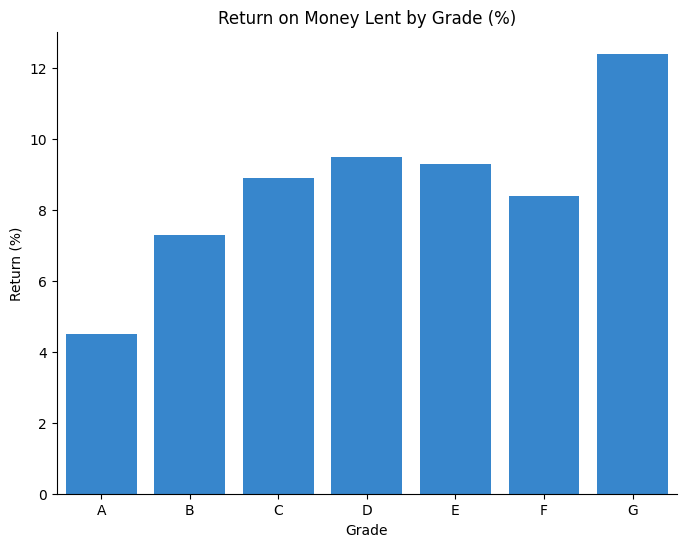

In [63]:
#return on money lent by grade
plt.figure(figsize=(8,6))
sns.barplot(x=grade_profit.index,y=grade_profit['roi_%'].values)
plt.title('Return on Money Lent by Grade (%)')
plt.xlabel('Grade')
plt.ylabel('Return (%)')
plt.gca().spines[['top','right']].set_visible(False)
plt.savefig('charts/24_roi_by_grade.png',dpi=150,bbox_inches='tight')
plt.show()

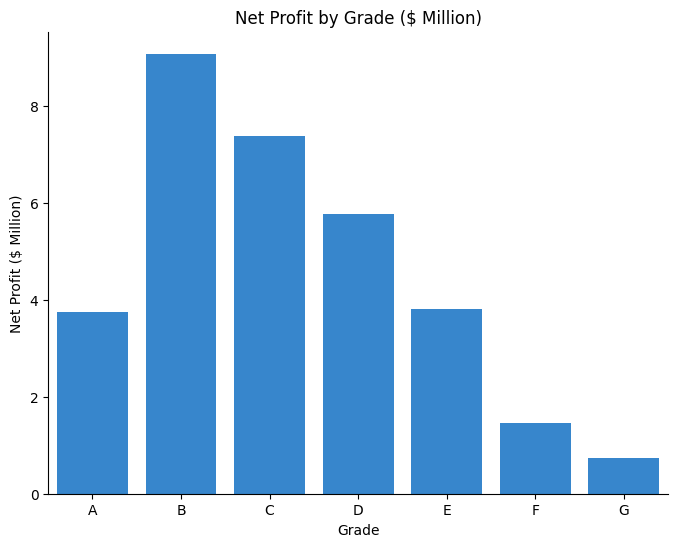

In [64]:
#net profit by grade
plt.figure(figsize=(8,6))
sns.barplot(x=grade_profit.index,y=grade_profit['net_profit_$M'].values)
plt.title('Net Profit by Grade ($ Million)')
plt.xlabel('Grade')
plt.ylabel('Net Profit ($ Million)')
plt.gca().spines[['top','right']].set_visible(False)
plt.savefig('charts/24b_net_profit_by_grade.png',dpi=150,bbox_inches='tight')
plt.show()

**Insights**
- **Grade A is the safest but earns the lowest return (4.5%)** and only \$3.8M profit, even though it is 20% of the money lent.
- **Grades B and C produce most of the profit (\$9.1M and \$7.4M)** with moderate risk. Grades D and E have the best returns among larger groups (9.5% and 9.3%): their higher interest rates more than pay for their higher defaults.
- Grades F and G earn good returns on paper (8.4% and 12.4%), but they are small groups (4% and 1% of lending), only worth \$1.5M and \$0.7M, and the risk of loss is very high.

### Profitability by Purpose and Term

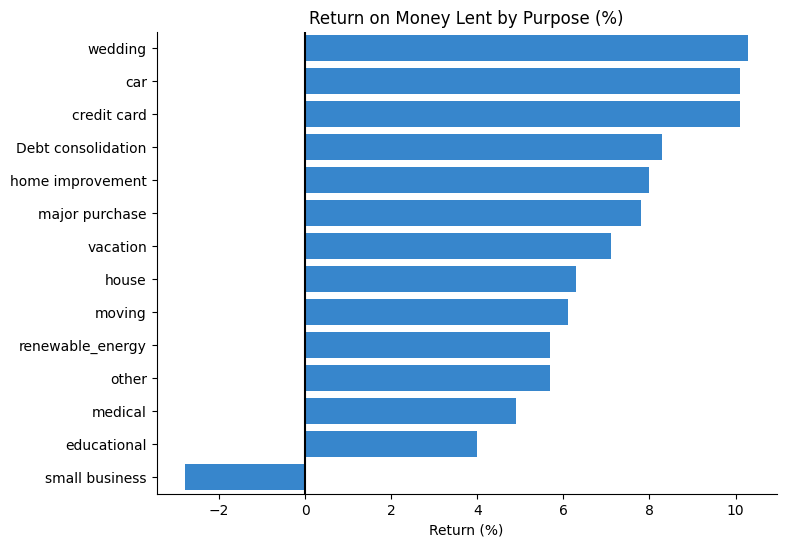

,loan_amount,total_payment,roi_%
purpose,,,
wedding,8907125,9828997,10.3
car,9842050,10833680,10.1
credit card,56934525,62694000,10.1
Debt consolidation,221847000,240196125,8.3
home improvement,31649250,34190490,8.0
major purchase,16790775,18108022,7.8
vacation,1927525,2065028,7.1
house,4525375,4811249,6.3
moving,3654250,3875766,6.1


In [65]:
#return on money lent by purpose (finished loans)
purpose_profit=df_resolved.groupby('purpose')[['loan_amount','total_payment']].sum()
purpose_profit['roi_%']=((purpose_profit['total_payment']-purpose_profit['loan_amount'])/purpose_profit['loan_amount']*100).round(1)
purpose_profit=purpose_profit.sort_values('roi_%',ascending=False)

plt.figure(figsize=(8,6))
sns.barplot(x=purpose_profit['roi_%'].values,y=purpose_profit.index)
plt.axvline(0,color='black')
plt.title('Return on Money Lent by Purpose (%)')
plt.xlabel('Return (%)')
plt.ylabel('')
plt.gca().spines[['top','right']].set_visible(False)
plt.savefig('charts/25_roi_by_purpose.png',dpi=150,bbox_inches='tight')
plt.show()
purpose_profit

In [66]:
#return on money lent by term
term_profit=df_resolved.groupby('term')[['loan_amount','total_payment']].sum()
term_profit['roi_%']=((term_profit['total_payment']-term_profit['loan_amount'])/term_profit['loan_amount']*100).round(1)
term_profit

,loan_amount,total_payment,roi_%
term,,,
36 months,273041225,294709458,7.9
60 months,143849350,154161561,7.2


**Insights**
- **Small business is the only purpose that loses money (−2.8% return)**: \$22.8M was lent and only \$22.1M came back. This is a high-volume risky segment (1,703 finished loans).
- The best returns come from **wedding (10.3%), credit card (10.1%), car (10.1%)** and debt consolidation earns a solid 8.3% on a very large base.
- **60-month loans return less (7.2%) than 36-month loans (7.9%)** even though they carry more than double the default risk, and the money is tied up for longer. They are not rewarding the lender for the extra risk and time.

## 10. Geographic Analysis

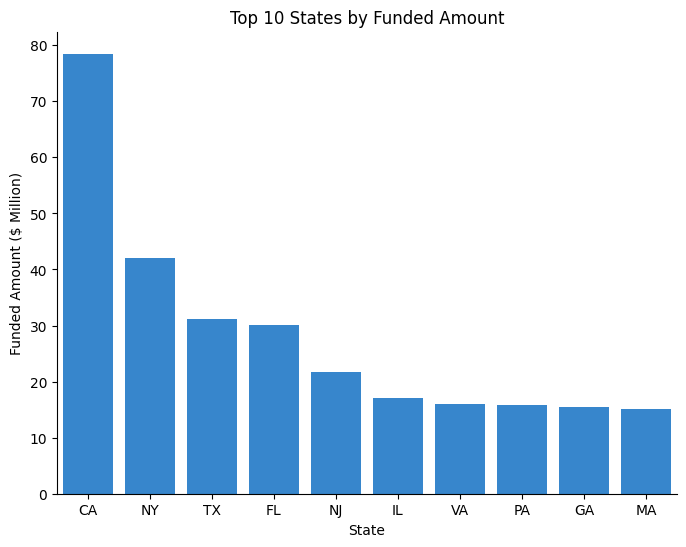

In [67]:
#top 10 states by funded amount
state_funded=(df.groupby('address_state')['loan_amount'].sum()/1000000).sort_values(ascending=False).head(10)

plt.figure(figsize=(8,6))
ax=sns.barplot(x=state_funded.index,y=state_funded.values)
plt.title('Top 10 States by Funded Amount')
plt.xlabel('State')
plt.ylabel('Funded Amount ($ Million)')
plt.gca().spines[['top','right']].set_visible(False)
plt.savefig('charts/26_top_states_funded.png',dpi=150,bbox_inches='tight')
plt.show()

In [68]:
#share of total funded amount held by the top 4 states
top4=df.groupby('address_state')['loan_amount'].sum().sort_values(ascending=False).head(4)
print(f'Top 4 states: {list(top4.index)}')
print(f'Share of total funded amount: {round(top4.sum()/df["loan_amount"].sum()*100,1)}%')

Top 4 states: ['CA', 'NY', 'TX', 'FL']
Share of total funded amount: 41.7%


States with at least 300 finished loans: 27


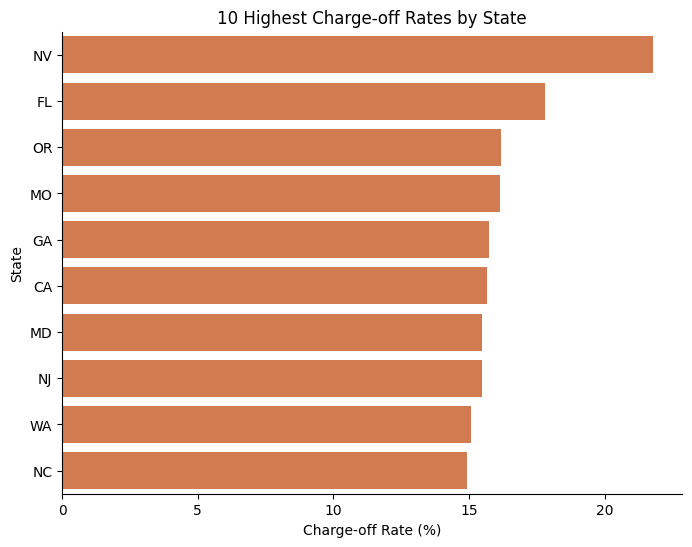

In [69]:
#charge-off rate by state (only states with at least 300 finished loans, so the rate is reliable)
state_risk=df_resolved.groupby('address_state').agg(loans=('id','count'),charge_off_rate=('is_bad','mean'))
state_risk=state_risk[state_risk['loans']>=300]
state_risk['charge_off_rate']=state_risk['charge_off_rate']*100
state_risk=state_risk.sort_values('charge_off_rate',ascending=False)
print(f'States with at least 300 finished loans: {len(state_risk)}')

plt.figure(figsize=(8,6))
highest=state_risk.head(10)
ax=sns.barplot(x=highest['charge_off_rate'].values,y=highest.index,color='#E8743B')
plt.title('10 Highest Charge-off Rates by State')
plt.xlabel('Charge-off Rate (%)')
plt.ylabel('State')
plt.gca().spines[['top','right']].set_visible(False)
plt.savefig('charts/27_chargeoff_by_state.png',dpi=150,bbox_inches='tight')
plt.show()

In [70]:
#the 5 safest states
state_risk.tail(5).round(1)

,loans,charge_off_rate
address_state,,
CO,744,12.2
MA,1268,11.8
AL,416,11.8
PA,1436,11.8
TX,2597,11.6


**Insights**
- **The portfolio is concentrated:** California, New York, Texas and Florida hold about **42% of all money lent**. California alone is 18%.
- **Nevada (21.8%) and Florida (17.8%) have the highest charge-off rates.** Florida matters most because it is large (2,691 finished loans) and earns only a 4.2% return.
- **California, the biggest market, is also above average (15.7%).** Texas (11.6%), Pennsylvania and Massachusetts (11.8%) are the safest large markets.

## 11. Correlation Analysis

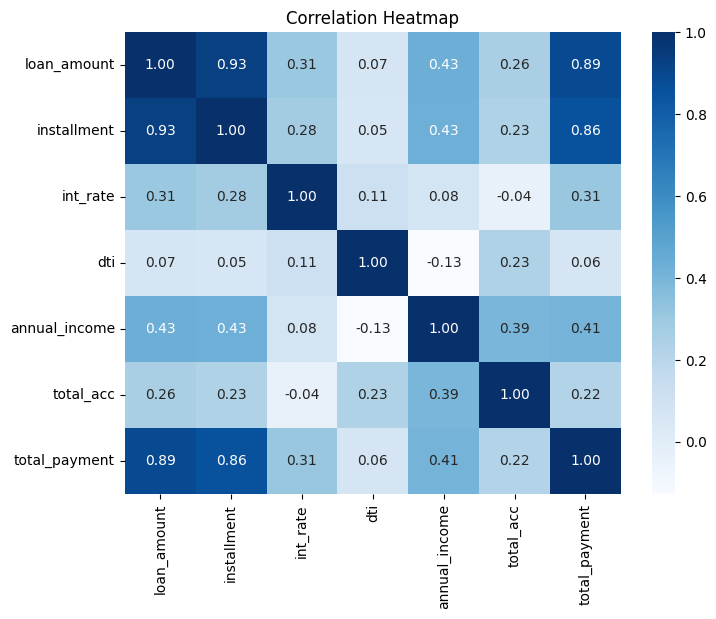

In [71]:
#correlation between numeric columns
num_cols=['loan_amount','installment','int_rate','dti','annual_income','total_acc','total_payment']
plt.figure(figsize=(8,6))
sns.heatmap(data=df[num_cols].corr(),annot=True,fmt='.2f',cmap='Blues')
plt.title('Correlation Heatmap')
plt.savefig('charts/28_correlation_heatmap.png',dpi=150,bbox_inches='tight')
plt.show()

**Insights**
- `loan_amount`, `installment` and `total_payment` move together very strongly (0.86–0.93), which is expected: a bigger loan means a bigger instalment and more money collected.
- **Interest rate is only moderately linked to loan amount (0.31)**: bigger loans are priced somewhat higher, but the rate depends mostly on the grade.
- **Annual income has a moderate link with loan amount (0.43)**: higher earners borrow more. DTI is only weakly linked to the other columns (0.23 at most), so it adds separate information when judging a borrower.

## 12. Key Findings & Recommendations

### Key Findings
| Area | Finding |
|---|---|
| **Portfolio size** | 38,576 loans, \$435.8M funded, \$473.1M received, average interest rate 12.05%, average DTI 13.33% |
| **Growth** | Applications +85% and funded amount +116% from January to December; average loan size +17%; average interest rate up from 11.5% to 12.4% |
| **Loan quality** | 86.18% good loans and 13.82% bad loans; charge-off rate of finished loans is 14.2% |
| **Profitability** | Fully Paid loans earned +\$60.2M, charge-offs lost \$28.2M, net profit \$32.0M (7.7% return); charge-offs erase about 47% of good-loan profit |
| **Grade** | Charge-off rate rises from 5.7% (A) to 33.1% (G); grades B and C earn the most profit (\$9.1M, \$7.4M), grade A the lowest return (4.5%) |
| **Term** | 60-month loans: 25.0% charge-off vs 10.7%, and a lower return (7.2% vs 7.9%) |
| **Purpose** | Debt consolidation is 53% of the money lent; small business has a 26.7% charge-off rate and the only negative return (−2.8%) |
| **Borrower profile** | Risk is higher for larger loans (20% above \$20K), low incomes (17.6% below \$30K) and higher DTI; employment length and home ownership matter little |
| **Verification** | Verified loans default more (15.6%) than non-verified (12.4%), so verification is not reducing risk on its own |
| **Geography** | Top 4 states hold about 42% of lending; Nevada and Florida have the highest charge-off rates |

### Recommendations
1. **Tighten 60-month lending.** Require a higher grade (B or better) or a lower maximum amount for 60-month loans, and re-price them, since they default 2.3 times more but return less.
2. **Fix or restrict small business loans.** Raise rates, lower the maximum amount or require extra documents – this segment loses money today.
3. **Grow the profitable middle (grades B, C and selected D).** Grade A is safe but low-yield and F/G are too risky; B and C give the best balance of volume, return and risk.
4. **Put stricter checks on large loans.** Add DTI and income limits for loans above \$15,000, where charge-offs reach 17–20%.
5. **Review the verification process.** Verified borrowers are not safer; check what is being verified and use risk-based rather than blanket verification.
6. **Limit geographic concentration.** Set exposure limits for California and review underwriting in Nevada and Florida.
7. **Watch the growth quality.** Loans are getting bigger and more expensive each month; track newer loans by month of issue so risk is caught early, because December loans have not had time to default yet.
8. **Extend the dashboard with a Risk page** showing charge-off rate by grade, term and purpose, so these findings can be monitored every month.

### Limitations
- The data covers **one year (2021)**, so long-term trends and seasonality cannot be confirmed.
- **Current loans (1,098) are excluded** from risk and profit analysis; they are all 60-month loans, so 60-month results are partly incomplete.
- Return is a **simple return** (not annualised), and the data does not include recovery costs, so true profit may be lower.
- Relationships shown are patterns, **not proof of cause** (for example the verification result).